# Notebook 3 — Regresión de la nota media del 2º semestre

Predecimos la variable continua `nota_media_2sem` a partir de las características
del estudiante y su desempeño en el 1er semestre, evitando data leakage.

La lógica está en `src/regresion.py`.

## Modelos

Probamo modelos desde lo más simple a lo no lineal:

- **Regresión lineal simple** (sin regularizar) — baseline.
- **Ridge** (L2) — regulariza estabilizando coeficientes
- **Lasso** (L1) — fuerza coeficientes a cero, haciendo selección automática
  de variables.
- **ElasticNet** (L1+L2) — combinación de ambas.
- **SVR lineal** — alternativa con pérdida `epsilon`-insensible.
- **SVR RBF** — kernel trick, mapea a dimensión infinita
- **Random Forest Regressor** — no lineal, robusto a multicolinealidad, con
  `feature_importances` interpretables.

## Consideraciones en el preprocesado

**Anti data-leakage.** El dataset de regresión se construyó eliminando todas
las variables del 2º semestre distintas del target. `cargar_datos` verifica
esta propiedad y aborta si encuentra alguna columna que contamine.

**Exclusión de abandonos.** También se excluyeron los alumnos con nota 0.0
en 1er o 2º semestre. Un 0.0 en este contexto no se ha considerado como rendimiento bajo, sino
 como abandono, Mezclarlo con notas reales crearía una distribución
bimodal que ningún regresor continuo podría ajustar correctamente.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import regresion
from configuracion import (
    REGRESION_TRAIN, REGRESION_TEST,
    DIAGNOSTICO_PREFIX, FEATURE_IMPORTANCE_REG,
    RESUMEN_REGRESION, PREDICCIONES_REGRESION,
    RESULTS_DIR,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Train: {REGRESION_TRAIN}')
print(f'Test: {REGRESION_TEST}')

Train: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\processed\datos_limpios_regresion_train.csv
Test: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\processed\datos_limpios_regresion_test.csv


## 1. Carga de datos

La función `cargar_datos` se aborta si detecta variables del 2º semestre
distintas del target en las features para asegurar que no se produce data-leakage

In [2]:
X_train, y_train, X_test, y_test = regresion.cargar_datos(
    str(REGRESION_TRAIN), str(REGRESION_TEST))

print(f'Train: {X_train.shape[0]} registros × {X_train.shape[1]} features')
print(f'Test:  {X_test.shape[0]} registros')
print(f'\nTarget nota_media_2sem:')
print(f'  rango train: {y_train.min():.2f} a {y_train.max():.2f}')
print(f'  media train: {y_train.mean():.2f}')
print(f'  std train: {y_train.std():.2f}')
print('\nComprobación anti-leakage: OK.')

Train: 2750 registros × 30 features
Test:  688 registros

Target nota_media_2sem:
  rango train: 10.00 a 18.57
  media train: 12.78
  std train: 1.39

Comprobación anti-leakage: OK.


### 1.1 Distribución del target

Visualizamos el target para entender qué estamos prediciendo y posteriormente comprobar que los resultados obtenidos son razonables.

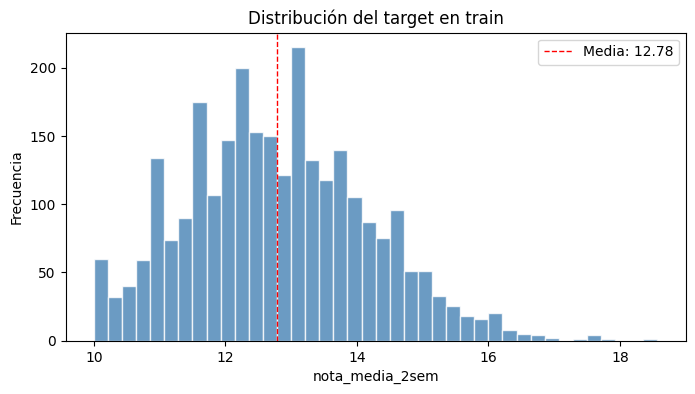

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=40, color='steelblue', alpha=0.8, edgecolor='white')
ax.axvline(y_train.mean(), color='red', ls='--', lw=1, label=f'Media: {y_train.mean():.2f}')
ax.set_xlabel('nota_media_2sem')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución del target en train')
ax.legend()
plt.show()

Como casi todas las notas son muy parecidas (están amontonadas entre 10 y 18), es muy difícil 
que el modelo acierte el número exacto. No es que todos los modelos sean sea malos, es que al variar los datos 
tan poco, cualquier pequeño fallo parece un error gigante. Por eso, aunque el modelo sea 
bueno, nunca tendremos una puntuación de precisión ($R^2$) perfecta.

## 2. Preprocesador

Igual que en clasificación: `StandardScaler` para numéricas y `OneHotEncoder` para categóricas. Todo dentro de un
pipeline para que el `fit` sólo vea el fold de entrenamiento en cada
iteración de la CV.

In [4]:
preprocesador = regresion.construir_preprocesador(X_train)
cols_num = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'Numéricas ({len(cols_num)}): {cols_num}')
print(f'\nCategóricas ({len(cols_cat)}): {cols_cat}')

Numéricas (14): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib', 'asignaturas_1sem_cursadas_normales', 'asignaturas_1sem_arrastradas']

Categóricas (16): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 2.5 Baseline (DummyRegressor)

Al igual que en clasificación, Antes de entrenar ningún modelo establecemos un baseline
con un `DummyRegressor`.

Empleamos dos estrategias:

| Estrategia | Predicción |
|---|---|
| `mean` | Siempre predice la media del train |
| `median` | Siempre predice la mediana del train |

Para que podamos considerar el modelo como útil, debe tener un RMSE por debajo
del RMSE baseline.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

estrategias_reg = ['mean', 'median']
filas_baseline_reg = []

for estrategia in estrategias_reg:
    dummy = DummyRegressor(strategy=estrategia)
    dummy.fit(X_train, y_train)
    y_pred_dummy = dummy.predict(X_test)
    r2   = r2_score(y_test, y_pred_dummy)
    rmse = mean_squared_error(y_test, y_pred_dummy) ** 0.5
    mae  = mean_absolute_error(y_test, y_pred_dummy)
    filas_baseline_reg.append({
        'modelo': f'Dummy ({estrategia})',
        'r2_test': r2, 'rmse_test': rmse, 'mae_test': mae})
    print(f"── Dummy strategy='{estrategia}' ──")
    print(f"  R²={r2:.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}")
    print(f"  (predice siempre {dummy.constant_.flat[0]:.4f})\n")

df_baseline_reg = pd.DataFrame(filas_baseline_reg)

── Dummy strategy='mean' ──
  R²=-0.0097  RMSE=1.3312  MAE=1.0673
  (predice siempre 12.7822)

── Dummy strategy='median' ──
  R²=-0.0001  RMSE=1.3248  MAE=1.0598
  (predice siempre 12.6667)



## 3. Definición de modelos y grids

In [6]:
modelos = regresion.definir_modelos_y_grids(preprocesador)
for nombre, (_, grid) in modelos.items():
    n_combos = int(np.prod([len(v) for v in grid.values()])) if grid else 1
    print(f'  {nombre:28s}  {n_combos:3d} combinaciones')

  Regresion_lineal_simple         1 combinaciones
  Ridge                           7 combinaciones
  Lasso                           7 combinaciones
  ElasticNet                     20 combinaciones
  SVR_linear                      9 combinaciones
  SVR_RBF                        36 combinaciones
  RandomForest                   36 combinaciones


## 4. Entrenamiento con validación cruzada

`KFold(5)` con `scoring='r2'`. Por cada combinación se entrenan 5 modelos.
El SVR-RBF es el más lento ($O(n^2)$), puede tardar unos minutos.

In [7]:
resultados = regresion.entrenar_modelos(modelos, X_train, y_train, verbose=0)


------------------------------------------------------------
  Entrenando: Regresion_lineal_simple
------------------------------------------------------------
Mejor R² (CV):   -372718553613577792.0000
Mejores params:  {}

------------------------------------------------------------
  Entrenando: Ridge
------------------------------------------------------------
Mejor R² (CV):   0.5049
Mejores params:  {'reg__alpha': 100}

------------------------------------------------------------
  Entrenando: Lasso
------------------------------------------------------------
Mejor R² (CV):   0.5046
Mejores params:  {'reg__alpha': 0.01}

------------------------------------------------------------
  Entrenando: ElasticNet
------------------------------------------------------------
Mejor R² (CV):   0.5070
Mejores params:  {'reg__alpha': 0.01, 'reg__l1_ratio': 0.3}

------------------------------------------------------------
  Entrenando: SVR_linear
-------------------------------------------------

## 5. Evaluación en test

Métricas reportadas:

- **R²**: proporción de varianza explicada (0 = modelo constante, 1 = perfecto).
- **RMSE**: error cuadrático medio, penaliza errores grandes.
- **MAE**: error absoluto medio, más interpretable directamente en la escala
  de las notas.

In [8]:
df_resumen = regresion.evaluar_en_test(resultados, X_test, y_test, path_resumen_csv=str(RESUMEN_REGRESION))

 Regresion_lineal_simple    R²=0.4914  RMSE=0.9447  MAE=0.7321
 Ridge                      R²=0.5032  RMSE=0.9337  MAE=0.7210
 Lasso                      R²=0.5002  RMSE=0.9366  MAE=0.7203
 ElasticNet                 R²=0.5051  RMSE=0.9320  MAE=0.7191
 SVR_linear                 R²=0.4957  RMSE=0.9407  MAE=0.7239
 SVR_RBF                    R²=0.5030  RMSE=0.9339  MAE=0.7176
 RandomForest               R²=0.5281  RMSE=0.9100  MAE=0.6955

------------------------------------------------------------
  RESUMEN COMPARATIVO (ordenado por R² en test)
------------------------------------------------------------
                 modelo         r2_cv  r2_test  rmse_test  mae_test                                                               mejores_params
           RandomForest  5.226010e-01 0.528097   0.910029  0.695481 {'reg__max_depth': 10, 'reg__min_samples_leaf': 1, 'reg__n_estimators': 500}
             ElasticNet  5.069974e-01 0.505063   0.931973  0.719060                               

### 5.1 Tabla comparativa

In [9]:
# Tabla unificada: modelos reales + baseline
df_comparacion_reg = pd.concat([
    df_resumen[['modelo', 'r2_test', 'rmse_test', 'mae_test']],
    df_baseline_reg,
], ignore_index=True).sort_values('r2_test', ascending=False)

rmse_baseline = df_baseline_reg.loc[df_baseline_reg['modelo'] == 'Dummy (mean)', 'rmse_test'].values[0]
df_comparacion_reg['reduccion_rmse_vs_mean'] = (
    (rmse_baseline - df_comparacion_reg['rmse_test']) / rmse_baseline * 100
).map(lambda x: f'{x:+.1f}%')

df_comparacion_reg.reset_index(drop=True)

,modelo,r2_test,rmse_test,mae_test,reduccion_rmse_vs_mean
0,RandomForest,0.528097,0.910029,0.695481,+31.6%
1,ElasticNet,0.505063,0.931973,0.719060,+30.0%
2,Ridge,0.503223,0.933704,0.720984,+29.9%
3,SVR_RBF,0.503015,0.933900,0.717617,+29.8%
4,Lasso,0.500160,0.936578,0.720343,+29.6%
5,SVR_linear,0.495748,0.940702,0.723893,+29.3%
6,Regresion_lineal_simple,0.491429,0.944723,0.732068,+29.0%
7,Dummy (median),-0.000129,1.324819,1.059836,+0.5%
8,Dummy (mean),-0.009718,1.331155,1.067265,+0.0%


In [10]:
df_resumen[['modelo', 'r2_cv', 'r2_test', 'rmse_test', 'mae_test']]

,modelo,r2_cv,r2_test,rmse_test,mae_test
0,RandomForest,5.226010e-01,0.528097,0.910029,0.695481
1,ElasticNet,5.069974e-01,0.505063,0.931973,0.719060
2,Ridge,5.048506e-01,0.503223,0.933704,0.720984
3,SVR_RBF,5.342575e-01,0.503015,0.933900,0.717617
4,Lasso,5.046261e-01,0.500160,0.936578,0.720343
5,SVR_linear,5.008726e-01,0.495748,0.940702,0.723893
6,Regresion_lineal_simple,-3.727186e+17,0.491429,0.944723,0.732068


### 5.2 Interpretación comparativa


- Si Regresion_Lineal_Simple, Ridge y SVR RBF rinden de forma parecida, indica que la relación
  `target - features` es lineal: no hay no linealidades que el kernel pueda explotar.
- Si Lasso iguala o supera a Ridge con muchos coeficientes a cero, hay
  redundancia alta entre variables (consistente con la multicolinealidad
  entre las variables del 1er semestre).
- Si Random Forest gana claramente, hay estructura no lineal relevante.

## 6. Diagnóstico gráfico del mejor modelo

Para el modelo con mayor R² en test, visualizamos:

- **Predicho vs real**: idealmente los puntos caen sobre la diagonal.
- **Residuos vs predicho**: idealmente una nube sin estructura alrededor de 0.
  Cualquier patrón (curvatura, embudo, bandas) indica que el modelo está
  perdiendo señal.

Mejor modelo en test: RandomForest


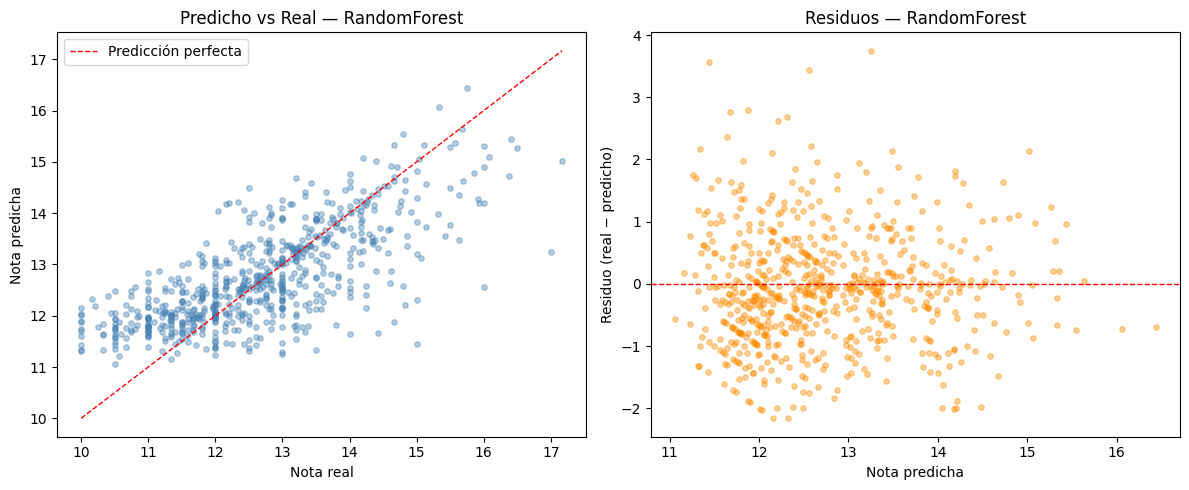

In [11]:
nombre_mejor = df_resumen.iloc[0]['modelo']
print(f'Mejor modelo en test: {nombre_mejor}')

fig_diag = regresion.diagnostico_grafico(
    nombre_mejor, resultados[nombre_mejor], X_test, y_test,
    path_fig=str(DIAGNOSTICO_PREFIX) + f'{nombre_mejor}.png')
plt.show()

**Lectura:**

- La distribución de los residuos es una nube uniforme que no sigue ninguna distribución aparente 
  por lo que estamos ante un caso de homocedasticidad, que es justamente lo que buscamos.

Con un modelo lineal (Ridge, Lasso) estos patrones suelen ser menos marcados
porque no hay averaging.

### 6.1 Diagnóstico del Lasso para comparar

Conviene comparar el diagnóstico del modelo no lineal (el que mejor se ajusta a este problema) con el de un
modelo lineal para ver el efecto del shrinkage.

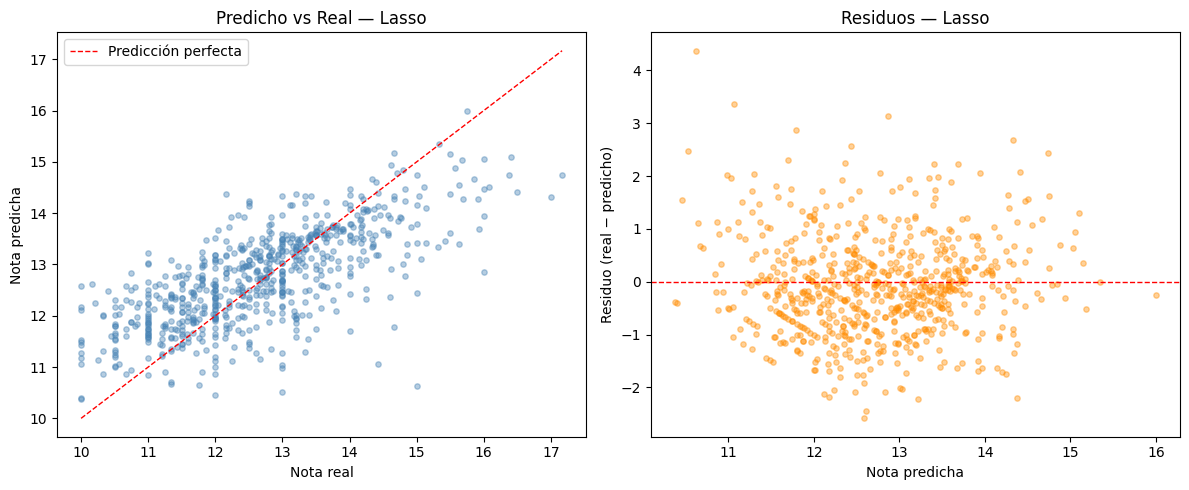

In [12]:
if 'Lasso' in resultados and nombre_mejor != 'Lasso':
    fig_lasso = regresion.diagnostico_grafico(
        'Lasso', resultados['Lasso'], X_test, y_test,
        path_fig=str(DIAGNOSTICO_PREFIX) + 'Lasso.png',
    )
    plt.show()

## 7. Interpretabilidad

### 7.1 Coeficientes del Lasso

Lasso fuerza coeficientes a cero, lo que ofrece una selección automática de
las variables más informativas. El signo indica la dirección del efecto,
interpretable sobre variables ya estandarizadas.

In [13]:
df_coefs = regresion.coeficientes_lasso(resultados['Lasso'], top_n=15)
df_coefs


  Lasso: 22 / 110 variables con coef != 0


,variable,coeficiente
0,nota_media_1sem,0.762256
1,asignaturas_1sem_aprobadas,0.207833
2,curso_enfermeria,0.200500
3,curso_educacion_basica,-0.184094
4,curso_diseno_de_comunicacion,-0.180615
5,asignaturas_1sem_arrastradas,-0.148279
6,asignaturas_1sem_cursadas_normales,-0.095974
7,deudor_no,0.083598
8,nota_admision,0.075436
9,curso_gestion_de_publicidad_y_marketing,0.074528


### 7.2 Importancia de variables del Random Forest

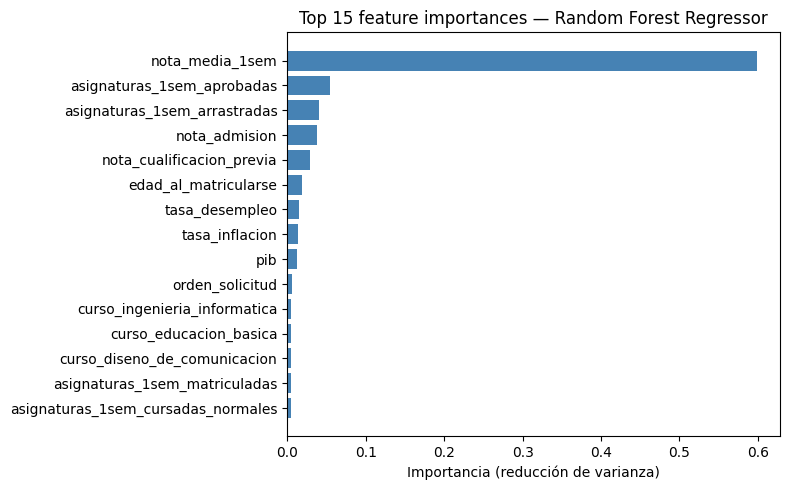

,variable,importancia
0,nota_media_1sem,0.598200
1,asignaturas_1sem_aprobadas,0.054003
2,asignaturas_1sem_arrastradas,0.041008
3,nota_admision,0.037607
4,nota_cualificacion_previa,0.028713
5,edad_al_matricularse,0.018791
6,tasa_desempleo,0.015123
7,tasa_inflacion,0.013527
8,pib,0.012749
9,orden_solicitud,0.006122


In [14]:
df_imp, fig_imp = regresion.importancia_rf(
    resultados['RandomForest'],
    top_n=15,
    path_fig=str(FEATURE_IMPORTANCE_REG))

plt.show()
df_imp

### 7.3 Interpretación

**Variable dominante:** `nota_media_1sem`. Esto es esperado ya que el rendimiento académico suele ser consistente de una semestre a otro.

**Matiz sobre la importancia de Gini.** En presencia de multicolinealidad
alta (ej. entre `asignaturas_1sem_aprobadas` y `nota_media_1sem`, que
están fuertemente correladas), el RF encuentra que una de ellas resume la información y las
demás quedan con importancia baja no porque no sean informativas, sino
porque son redundantes (explican lo mismo).

**Coincidencia Lasso y RF.** Si las top variables de ambas listas coinciden, tenemos evidencia robusta de su relevancia.
Si difieren, el RF probablemente está capturando efectos no lineales o
interacciones entre variables que el lasso no ha capturado.

## 8. Guardar predicciones del mejor modelo

In [16]:
preds = pd.DataFrame({
    'y_real': y_test.values,
    'y_pred': resultados[nombre_mejor].predict(X_test)})

preds.to_csv(PREDICCIONES_REGRESION, index=False)
print(f'Guardado: {PREDICCIONES_REGRESION}')
preds.head()

Guardado: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\results\predicciones_regresion.csv


,y_real,y_pred
0,12.714286,12.560138
1,14.333333,13.428923
2,11.250000,11.803792
3,11.832000,12.150757
4,10.333333,11.639317


## 9. Conclusiones

- El R² obtenido es relativamente bajo porque intentamos predecir una
  nota individual sólo a partir
  de información previa. Esto es consistente con que el target tiene una
  desviación típica pequeña (1.4) en un rango estrecho.
- El predictor dominante es el **rendimiento del 1er semestre**. Los modelos
  lineales regularizados y el RF coinciden en esta conclusión.
- Los modelos basados en árboles muestran **shrinkage** hacia la media del
  target: subestiman a los mejores estudiantes y
  sobreestiman a los peores.